# Hausaufgaben zu stetigen Verteilungen

# Gleichverteilung / Uniformverteilung

Ein Kaffeevollautomat benötigt für die Zubereitung eines großen Kaffees eine zufällige Zeit zwischen 60 und 90 Sekunden (alle Zeiten sind gleichwahrscheinlich). Die Zufallsvariable $X$ beschreibt diese Zubereitungszeit.

1. Du möchtest wissen, wie hoch die Dichte der Verteilung an einem beliebigen Punkt innerhalb des Intervalls $[60, 90]$ ist. Berechne die Dichte (hierfür gibt es zwei Wege).
2. Kannst du die Wahrscheinlichkeit $P(X = 70)$, dass ein Kaffe exakt 70 Sekunden braucht, berechnen?
3. Berechne die Wahrscheinlichkeit, dass der Kaffe zwischen 70 und 80 Sekunden zur Zubereitung braucht (also $P(70 \le X \le 80)$).

In [1]:
from scipy.stats import uniform

density = uniform.pdf(70, loc=60, scale=30)
p_exact = uniform.pdf(70, loc=60, scale=30) * 0
p_intervall = uniform.cdf(80, loc=60, scale=30) - uniform.cdf(70, loc=60, scale=30)

print(f"Ergebnis P(70 <= X <= 80): {p_intervall:.2%}")

Ergebnis P(70 <= X <= 80): 33.33%


# Autobahnkreuzung erweitert
Wir betrachten dieselbe Autobahnkreuzung wie für die Poisson-Verteilung der letzten Lektion. Im langjährigen Durchschnitt passieren hier weiterhin 3 Unfälle pro Jahr. Wir wollen uns jetzt die Dauer $T$ zwischen zwei Unfällen anschauen und modellieren. 
1. Welche Wahrscheinlichkeitsverteilung eignet sich zum Modellieren dieser Zeit $T$?
2. Welchen Parameter brauchen wir hierfür und welchen Wert hat er nach der Aufgabenstellung?
3. Berechne, wie wahrscheinlich es ist, dass nach einem Unfall weniger als ein halbes Jahr (0,5 Jahre) vergeht, bis der nächste Unfall passiert.

In [3]:
from scipy.stats import expon

lambd = 3
scale_exp = 1 / lambd
prob = expon.cdf(0.5, scale=scale_exp)

print(f"Wahrscheinlichkeit, dass zwischen zwei Unfällen höchstens ein halbes Jahr liegt: {prob:.2%}")

Wahrscheinlichkeit, dass zwischen zwei Unfällen höchstens ein halbes Jahr liegt: 77.69%


## Präsentationen
Eine Gruppe aus der Weiterbildung hat ein EDA-Projekt entwickelt. Zum Abschluss präsentieren die Teilnehmenden ihr Projekt vor einer Jury.

Aus früheren Gruppen ist bekannt, dass die Präsentationsdauer der Gruppen im Schnitt 20 Minuten ist, wobei eine Standardabweichung von bis zu 3 Minuten vorkommen kann.

1. Welche Verteilung ist bei diesen Größen geeignet?
2. Berechne die Wahrscheinlichkeit, dass eine Präsentation zwischen 18 und 25 Minuten dauert.
3. Wir wollen eine Visualisierung von dieser Verteilung mit Matplotlib erstellen. Der Code zum Plotten wird vorgegeben. Ergänze die Berechnung der `probability distribution function`, damit die Kurve eingezeichnet wird.
*Hinweis:* Den Code der Visualisierung selber brauchst du hier noch nicht verstehen.

In [ ]:
from scipy.stats import norm
mu = 20
sigma = 3
p = norm.cdf(25, loc=mu, scale=sigma) - norm.cdf(18, loc=mu, scale=sigma)

print(f"Wahrscheinlichkeit für eine Präsentation zwischen 18 und 25 Minuten: {p:.4f}")

Wahrscheinlichkeit für eine Präsentation zwischen 18 und 25 Minuten: 0.6997


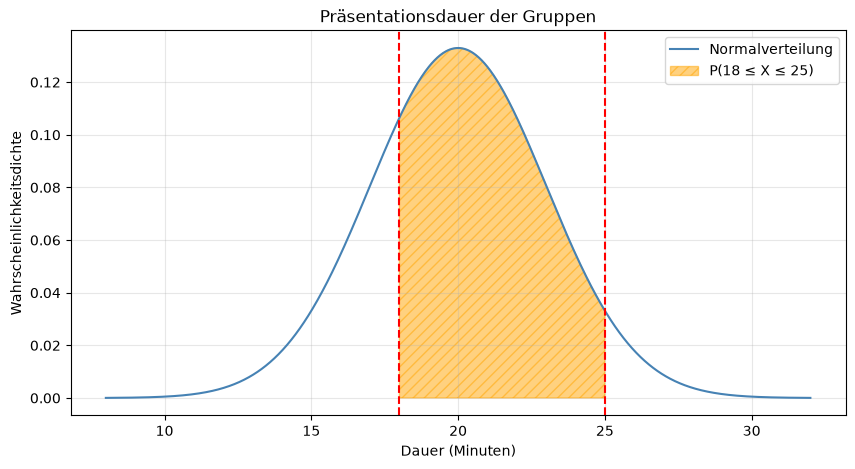

In [6]:
# Visualisierung
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(8, 32, 1000)
y = norm.pdf(x, loc=mu, scale=sigma)

plt.figure(figsize=(10, 5))
plt.plot(x, y, label="Normalverteilung", color="steelblue")

# Bereich 18 bis 25 Minuten hervorheben
x_fill = np.linspace(18, 25, 1000)
y_fill = norm.pdf(x_fill, loc=mu, scale=sigma)

plt.fill_between(x_fill, y_fill, color="orange", alpha=0.5,
                 hatch="///", label="P(18 ≤ X ≤ 25)")

plt.axvline(18, color="red", linestyle="--")
plt.axvline(25, color="red", linestyle="--")
plt.title("Präsentationsdauer der Gruppen")
plt.xlabel("Dauer (Minuten)")
plt.ylabel("Wahrscheinlichkeitsdichte")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Optional: Log-Normalverteilung

Die Log-Normalverteilung ist eine stetige Wahrscheinlichkeitsverteilung für positive Werte. Eine Zufallsvariable heißt log-normalverteilt, wenn ihr Logarithmus normalverteilt ist.

Im Gegensatz zur Normalverteilung ist die Log-Normalverteilung rechtsschief: Viele Werte liegen im unteren Bereich, während wenige sehr große Werte einen langen rechten Rand bilden.

Die Log-Normalverteilung wird häufig für Größen verwendet, die:
- nur positive Werte annehmen können,
- stark rechtsschief verteilt sind,
- gelegentlich sehr große Ausreißer besitzen.

<div style="overflow-x:auto;">
<table style="width:100%; border-collapse:collapse;">
  <thead>
    <tr>
      <th style="border:1px solid #ccc; padding:8px;">Normalverteilung</th>
      <th style="border:1px solid #ccc; padding:8px;">Log-Normalverteilung</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="border:1px solid #ccc; padding:8px;">Körpergröße</td>
      <td style="border:1px solid #ccc; padding:8px;">Einkommen</td>
    </tr>
    <tr>
      <td style="border:1px solid #ccc; padding:8px;">Gewicht von Äpfeln</td>
      <td style="border:1px solid #ccc; padding:8px;">Vermögen</td>
    </tr>
    <tr>
      <td style="border:1px solid #ccc; padding:8px;">Messfehler</td>
      <td style="border:1px solid #ccc; padding:8px;">Unternehmensgrößen</td>
    </tr>
    <tr>
      <td style="border:1px solid #ccc; padding:8px;">Blutdruck</td>
      <td style="border:1px solid #ccc; padding:8px;">Dateigrößen</td>
    </tr>
    <tr>
      <td style="border:1px solid #ccc; padding:8px;">Prüfungsergebnisse</td>
      <td style="border:1px solid #ccc; padding:8px;">Immobilienpreise</td>
    </tr>
    <tr style="background:#fff8dc; font-weight:bold;">


## Aufgabe (Optional): Log-/Normalverteilung

Du untersuchst als Dataanalyst die Dateigrößen (in Megabyte, MB) von 10.000 verschiedenen Apps in einem App Store. Dabei stellst du fest: Die allermeisten Apps sind relativ klein (z. B. zwischen 5 MB und 50 MB), wobei einige wenige extrem große Apps sind (z. B. riesige 3D-Spiele mit mehreren Gigabyte), die den Durchschnitt stark nach oben ziehen.  
Eine App kann niemals eine Dateigröße von 0 MB oder weniger haben.  

1. Welche Wahrscheinlichkeitsverteilung eignet sich besser, um die Dateigrößen dieser Apps zu modellieren: die Normalverteilung oder die Log-Normalverteilung? Begründe deine Entscheidung.
2. Angenommen, die Dateigrößen werden mit der oben gewählten Verteilung modelliert, bei der die Parameter einem Mittelwert von $\mu = 3$ und einer Standardabweichung von $\sigma = 0{,}8$ entsprechen. Berechne die Wahrscheinlichkeit, dass eine zufällig ausgewählte App kleiner als 20 MB ist.

In [ ]:
import numpy as np
from scipy.stats import lognorm

# 1

# Gegebene Parameter
mu = 3          # Mittelwert
sigma = 0.8     # Standardabweichung

# 2
limit_mb = 20
prob = ...

print(f"Wahrscheinlichkeit, dass eine App kleiner als {limit_mb} MB ist: {prob:.2%}")